# 15 · LLMOps with LangSmith: tracing, monitoring and evaluation

An LLM application fails in ways ordinary monitoring does not see. A hallucinated answer still returns `HTTP 200`. A prompt change quietly doubles the token bill. One slow tool drags the p99 latency. A retrieval regression lowers answer quality for a week before a customer complains. **Observability** means recording enough about every request to answer, after the fact: *what happened, how long did it take, what did it cost, and how good was it?*

**LangSmith** is LangChain's observability and evaluation platform, and its data model is very close to the ones used by Langfuse, Arize Phoenix and the OpenTelemetry GenAI conventions (similar concepts, not identical schemas):

| concept | what it is |
|---|---|
| **project** | a bucket of traces, usually one per app and environment |
| **trace** | one end-to-end request: a tree of **runs** |
| **run** (a *span* in OpenTelemetry) | one step with inputs, outputs, timing, error and a `run_type`: `llm`, `chain`, `retriever`, `tool`, `prompt`, `embedding`… |
| **metadata / tags** | key-values and labels on a run, used to filter (app version, user, experiment) |
| **thread** | the traces of one conversation, grouped by a `thread_id` (or `session_id`) metadata key |
| **feedback** | a score attached to a run: user thumbs, heuristic checks, LLM-as-judge |
| **dataset → experiment** | labelled examples, and one scored run of your app over them (offline evaluation) |

In this notebook we instrument a small support assistant (a LangGraph RAG graph plus a tool), send it some traffic, and then use the LangSmith SDK the way an on-call engineer would: latency percentiles, tokens, error rate, SLOs, online scores, PII redaction, sampling, export, and an offline experiment comparing two versions of the app.

**Without a LangSmith key** the notebook still runs: the app works, the evaluators run locally, and the cells that need the LangSmith server print that they were skipped. Add `LANGSMITH_TRACING=true` and `LANGSMITH_API_KEY` to `.env` to see everything.

## Background: observability for systems whose output is text

### Why LLM applications need their own kind of monitoring

Classical monitoring rests on the assumption that a request either succeeds or fails, and that a success is correct. LLM applications break that assumption in several ways at once:

- **Failures are semantic.** A wrong, ungrounded or unsafe answer is a successful HTTP response. Only something that reads the content can detect it.
- **Behaviour is non-deterministic and input-dependent.** The same code path produces different outputs for paraphrased inputs, and a provider can change a hosted model under the same name.
- **Requests are multi-step.** One user message can trigger retrieval, several model calls and tool calls. A slow or wrong answer has to be attributed to a step.
- **Cost is proportional to tokens**, and tokens depend on prompts, retrieved context and conversation length, all of which change with every release.
- **Quality is a distribution, not a bit.** "Is the app better after this change?" is a statistical question over many requests.

LLMOps therefore combines two traditions: **distributed tracing** from site-reliability engineering (what happened, where the time went) and **evaluation** from machine learning (how good the outputs are), applied continuously to production traffic.

### Traces and spans: where the data model comes from

The trace/span model comes from Google's **Dapper** (Sigelman et al., 2010, *Dapper, a Large-Scale Distributed Systems Tracing Infrastructure*). A **trace** is the record of one request; it is a tree of **spans**, each a timed operation with a parent. The key mechanism is **context propagation**: when a span starts a child operation, it passes along the trace id and its own span id, so the child can attach itself to the right parent, even across threads, processes or services. Dapper's ideas went into Zipkin, then OpenTracing and OpenCensus, which merged in 2019 into **OpenTelemetry** (OTel), today's vendor-neutral standard for traces, metrics and logs.

LangSmith's *runs* are spans with LLM-specific fields (inputs and outputs as messages, token usage, `run_type`). Inside one Python process the "context" is a context variable holding the current run; across processes LangSmith propagates it through headers, exactly as OTel does. The `dotted_order` field you will see in section 2 encodes the path from the root to each run (start time plus id at each level), so sorting by it reproduces the tree.

### The OpenTelemetry GenAI semantic conventions

A trace is only portable if everyone names things the same way. OTel's **GenAI semantic conventions** define standard span names and attributes for model calls, for example:

| attribute | meaning |
|---|---|
| `gen_ai.operation.name` | `chat`, `embeddings`, `execute_tool`, `invoke_agent`, ... |
| `gen_ai.provider.name` | the provider (earlier versions called this `gen_ai.system`) |
| `gen_ai.request.model`, `gen_ai.response.model` | the model asked for and the model that answered |
| `gen_ai.usage.input_tokens`, `gen_ai.usage.output_tokens` | token counts |
| `gen_ai.request.temperature`, `gen_ai.request.max_tokens` | sampling parameters |

They also define metrics such as the client operation duration, token usage and, for servers, time to first token. The conventions were still marked as *in development* at the time of writing, and attribute names have changed between versions (as `gen_ai.system` did), so check the current version before building dashboards on them. Their importance is strategic: an application instrumented with them can send its traces to LangSmith, Langfuse, Arize Phoenix, Datadog or Grafana without code changes, and LangSmith both exports and accepts OTel traces (section 11).

### Signals: traces, metrics, logs, and feedback

Observability is usually described with three kinds of telemetry: **traces** (the structure and timing of a request), **metrics** (aggregated numbers over time, cheap to store and alert on) and **logs** (discrete events). LLM systems add a fourth: **feedback**, a score attached to a trace after the fact, coming from users, heuristics, LLM judges or human reviewers. Feedback is what turns traces into a quality signal, and it is the link between monitoring and evaluation.

### Offline and online evaluation

| | offline evaluation | online evaluation |
|---|---|---|
| when | before a change ships | continuously, on production traffic |
| data | a fixed, labelled dataset | real requests, usually without reference answers |
| evaluators | reference-based (exact match, key facts, LLM judge with a reference) | reference-free (groundedness, format checks, judge without reference, user feedback) |
| answers the question | is version B better than version A on the cases we care about? | is production healthy today, and which traces should a human read? |
| main risk | the dataset stops representing real traffic | cheap signals are noisy; expensive ones can only run on a sample |

The two feed each other: bad production traces, once reviewed and labelled, become new dataset examples, so the offline set tracks what users actually ask. This loop is the core workflow of LLMOps.

### LLM-as-judge in brief

Many qualities (correctness of free text, helpfulness, tone) have no cheap deterministic metric. **LLM-as-judge** uses a strong model with a rubric as the evaluator. Zheng et al. (2023, *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena*) showed that strong judges agree with human preferences about as often as humans agree with each other, and also documented the biases that come with it: **position bias**, **verbosity bias** and **self-enhancement bias**. Section 10 discusses them and their mitigations next to the code.

### Key references

- Sigelman et al., 2010. *Dapper, a Large-Scale Distributed Systems Tracing Infrastructure.* Google technical report.
- OpenTelemetry. *Semantic conventions for generative AI systems* (opentelemetry.io, versioned with the OTel semantic conventions).
- Dean and Barroso, 2013. *The Tail at Scale.* Communications of the ACM.
- Beyer, Jones, Petoff and Murphy (eds.), 2016. *Site Reliability Engineering*, chapter "Service Level Objectives". O'Reilly.
- Zheng et al., 2023. *Judging LLM-as-a-Judge with MT-Bench and Chatbot Arena.*
- Liu et al., 2023. *G-Eval: NLG Evaluation using GPT-4 with Better Human Alignment.*
- Wang et al., 2023. *Large Language Models are not Fair Evaluators.*
- Verga et al., 2024. *Replacing Judges with Juries: Evaluating LLM Generations with a Panel of Diverse Models.*

In [1]:
import os, sys, json, time, random, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)
random.seed(0); np.random.seed(0)

from llm_edu_suite.config import setup, get_llm, get_embeddings
info = setup(project="llm-edu-suite-15-observability")           # loads .env, picks the LangSmith project, checks that Ollama is up

provider        : ollama
chat_model      : qwen2.5:3b
embedding_model : nomic-embed-text
ollama_running  : True
langsmith       : on (project: llm-edu-suite-15-observability)


In [2]:
import uuid, asyncio, tempfile, urllib.request
from langsmith import Client, traceable, tracing_context, evaluate
from langsmith.run_helpers import get_current_run_tree
from langsmith.run_trees import get_cached_client
from langchain_core.tracers.langchain import wait_for_all_tracers
from llm_edu_suite.config import langsmith_enabled

LS = langsmith_enabled()                          # True when .env has LANGSMITH_TRACING=true and an API key
PROJECT = "llm-edu-suite-15-observability"
EXEC_TAG = "exec-" + uuid.uuid4().hex[:8]         # a tag unique to this execution, so our queries only see today's runs
client = Client() if LS else None
print("LangSmith enabled:", LS, "| project:", PROJECT if LS else "-", "| execution tag:", EXEC_TAG)

LangSmith enabled: True | project: llm-edu-suite-15-observability | execution tag: exec-c721fdcc


The helpers below are plain Python (no network): the PII rules, a cheap groundedness heuristic, three evaluators and a percentile summary. They are tested in `tests/test_observability_langsmith.py`; we explain each one when we use it.

In [3]:
import re
import numpy as np
from pydantic import BaseModel, Field
from langsmith.anonymizer import create_anonymizer

# PII rules for LangSmith's anonymizer. Order matters: card numbers before phone numbers, or the phone rule eats them.
PII_RULES = [
    {"pattern": r"[\w.+-]+@[\w-]+\.[\w.-]+", "replace": "<email>"},
    {"pattern": r"\b\d(?:[ -]?\d){12,15}\b", "replace": "<card>"},
    {"pattern": r"\+?\d[\d ()-]{7,}\d", "replace": "<phone>"},
    {"pattern": r"\bsk-[A-Za-z0-9_-]{8,}", "replace": "<api-key>"},
]
redact = create_anonymizer(PII_RULES)          # a function dict -> dict (it rewrites every string inside, in place)

STOPWORDS = {"that", "this", "with", "from", "have", "your", "what", "when", "they", "there", "their", "will",
             "would", "about", "which", "into", "only", "also", "than", "then", "them", "were", "been", "does"}

def content_words(text: str) -> set:
    """Lower-cased words of 4+ letters plus every number; the words that carry the facts of an answer."""
    words = re.findall(r"[a-z0-9]+(?:[.-][a-z0-9]+)*", text.lower())
    return {w for w in words if (len(w) > 3 or any(ch.isdigit() for ch in w)) and w not in STOPWORDS}

def groundedness(answer: str, contexts: list) -> float:
    """Share of the answer's content words that also appear in the retrieved context (a cheap faithfulness proxy)."""
    words = content_words(answer)
    if not words:
        return 0.0
    return len(words & content_words(" ".join(contexts))) / len(words)

def _norm(s: str) -> str:
    return " ".join(re.findall(r"[a-z0-9]+", s.lower()))

def exact_match(outputs: dict, reference_outputs: dict) -> dict:
    """1 if the answer equals the reference after lower-casing and dropping punctuation."""
    return {"key": "exact_match", "score": float(_norm(outputs.get("answer", "")) == _norm(reference_outputs["answer"]))}

def contains_fact(outputs: dict, reference_outputs: dict) -> dict:
    """1 if the answer mentions every key fact. must_contain is a list of groups; any spelling in a group counts."""
    answer = outputs.get("answer", "").lower()
    hit = all(any(alt.lower() in answer for alt in group) for group in reference_outputs["must_contain"])
    return {"key": "contains_fact", "score": float(hit)}

class Grade(BaseModel):
    reasoning: str = Field(description="One short sentence comparing the answer with the reference.")
    correct: bool = Field(description="True only if the answer states the same key fact as the reference.")

JUDGE_PROMPT = """You are grading a customer-support answer against a reference answer.
The answer is correct only if it states the same key fact as the reference (the same number, duration or yes/no).
Answers that hedge, say "it depends", give a different number, or do not answer are incorrect. Ignore style.

Question: {question}
Reference answer: {reference}
Answer to grade: {answer}"""

def make_correctness_judge(judge_llm):
    """An LLM-as-judge evaluator in LangSmith's (inputs, outputs, reference_outputs) signature."""
    grader = judge_llm.with_structured_output(Grade)
    def correctness(inputs: dict, outputs: dict, reference_outputs: dict) -> dict:
        g = grader.invoke(JUDGE_PROMPT.format(question=inputs["question"], reference=reference_outputs["answer"],
                                              answer=outputs.get("answer", "")))
        return {"key": "correctness", "score": float(g.correct), "comment": g.reasoning}
    return correctness

def latency_summary(seconds) -> dict:
    """p50/p95/p99 and mean of a list of latencies (seconds)."""
    a = np.asarray([s for s in seconds if s is not None], dtype=float)
    if a.size == 0:
        return {"n": 0, "p50": float("nan"), "p95": float("nan"), "p99": float("nan"), "mean": float("nan")}
    return {"n": int(a.size), "p50": float(np.percentile(a, 50)), "p95": float(np.percentile(a, 95)),
            "p99": float(np.percentile(a, 99)), "mean": float(a.mean())}

## 1. The application: a LangGraph RAG graph over the company docs

The knowledge base is the four short policy documents in `data/sample_docs/`. Each sentence becomes one `Document`, embedded with `nomic-embed-text` into LangChain's `InMemoryVectorStore`. The graph has two nodes, `retrieve` and `generate`, like the RAG notebook (10), so we can concentrate on observing it.

In [4]:
from typing import TypedDict
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.prompts import ChatPromptTemplate
from langgraph.graph import StateGraph, START, END

docs_dir = os.path.join(ROOT, "data", "sample_docs")
documents = []
for fname in sorted(os.listdir(docs_dir)):
    for line in open(os.path.join(docs_dir, fname), encoding="utf-8"):
        line = line.strip()
        if line and not line.startswith("#"):
            documents.append(Document(page_content=line, metadata={"source": fname}))

llm = get_llm()                                   # ChatOllama(qwen2.5:3b, temperature=0)
with tracing_context(enabled=False):              # building the index is setup, not traffic: keep it out of the traces
    store = InMemoryVectorStore.from_documents(documents, get_embeddings())
    llm.invoke("Say OK.")                         # warm-up, so the first traced request does not pay the model load time
retriever = store.as_retriever(search_kwargs={"k": 3})

rag_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are the customer support assistant of an online shop. Answer the question in one sentence using only "
               "the context. If the context does not contain the answer, say you don't know.\n\nContext:\n{context}"),
    ("human", "{question}"),
])

class RAGState(TypedDict, total=False):
    question: str
    docs: list
    answer: str

def retrieve_node(state: RAGState) -> dict:
    return {"docs": retriever.invoke(state["question"])}

def generate_node(state: RAGState) -> dict:
    context = "\n".join(d.page_content for d in state["docs"])
    return {"answer": (rag_prompt | llm).invoke({"context": context, "question": state["question"]}).content}

graph = StateGraph(RAGState)
graph.add_node("retrieve", retrieve_node)
graph.add_node("generate", generate_node)
graph.add_edge(START, "retrieve"); graph.add_edge("retrieve", "generate"); graph.add_edge("generate", END)
rag_graph = graph.compile()
print(f"{len(documents)} sentences indexed from {len(os.listdir(docs_dir))} documents")

16 sentences indexed from 4 documents


## 2. Automatic tracing of LangChain and LangGraph

With `LANGSMITH_TRACING=true` in the environment, **every** LangChain and LangGraph call is traced with no code change: LangChain's callback system sends one run per runnable to LangSmith. The `config` argument adds a run name, tags and metadata to the root run (and tags and metadata are inherited by the children), which is how you later filter "all traces of app version 2 for customer X".

How it works under the hood: each run is a `RunTree` object kept in a context variable, so a nested call knows its parent. Finished runs go into an in-memory queue that a background thread uploads in batches, which is why tracing adds almost no latency to the request. The flip side is that runs reach the server a moment later; a script that exits right away should call `client.flush()` (or LangChain's `wait_for_all_tracers()`).

In [5]:
first_id = uuid.uuid4()
with tracing_context(tags=[EXEC_TAG]):
    out = rag_graph.invoke({"question": "How long does express shipping take?"},
                           config={"run_name": "rag_graph_demo", "run_id": first_id, "tags": ["demo"],
                                   "metadata": {"app_version": "rag-v1"}})
print("answer:", out["answer"])
print("retrieved:", [d.page_content[:60] for d in out["docs"]])

answer: Express delivery takes 1 to 2 business days.
retrieved: ['Express shipping delivers in 1 to 2 business days and costs ', 'Standard shipping takes 3 to 7 business days and is free for', 'We ship to 40 countries. International orders may pay custom']


To see what LangSmith stored, we query the runs back with the SDK. In `langsmith` 0.14 the query API is `client.runs.query(...)` (the older `client.list_runs` is deprecated). It is an **async** paginator, so we iterate it with `async for`; Jupyter lets us `await` at the top level of a cell. `selects` lists the fields we want, and `filter` uses LangSmith's filter language, e.g. `and(eq(run_type, "llm"), gt(latency, 5))` or `has(tags, "v2")`.

Because runs are uploaded in the background and then indexed by the server, `wait_for_runs` flushes the local queues and polls until the expected runs are there and none is still pending, with a timeout.

In [6]:
RUN_FIELDS = ["ID", "NAME", "RUN_TYPE", "STATUS", "START_TIME", "LATENCY_SECONDS", "PROMPT_TOKENS", "COMPLETION_TOKENS",
              "TOTAL_TOKENS", "TOTAL_COST", "ERROR", "TAGS", "METADATA", "TRACE_ID", "PARENT_RUN_IDS", "DOTTED_ORDER",
              "IS_ROOT", "THREAD_ID"]
project_id = None

async def query_runs(selects=RUN_FIELDS, **kwargs) -> list:
    """All runs of this notebook's project that match the filters (`async for` follows the pagination for us)."""
    return [r async for r in client.runs.query(project_ids=[project_id], selects=selects, **kwargs)]

def flush_traces():
    """Push every queued run to LangSmith: the traceable client and the LangChain tracer each have a queue."""
    get_cached_client().flush()
    wait_for_all_tracers()

async def wait_for_runs(expected: int = 1, timeout: float = 120, **kwargs) -> list:
    """Flush, then poll until at least `expected` runs match the filters, none is pending, and the count stops growing."""
    global project_id
    flush_traces()
    deadline, previous, runs = time.time() + timeout, -1, []
    while True:
        try:
            if project_id is None:
                project_id = str(client.read_project(project_name=PROJECT).id)
            runs = await query_runs(**kwargs)
        except Exception:                             # the project may not exist for a second or two after the first run
            runs = []
        if len(runs) >= expected and len(runs) == previous and all(r.status != "pending" for r in runs):
            return runs
        if time.time() > deadline:
            print(f"timeout: {len(runs)} runs available (expected at least {expected})")
            return runs
        previous = len(runs)
        await asyncio.sleep(3)

def print_tree(runs):
    """Print a trace as an indented tree, ordered the way LangSmith orders runs (by dotted_order)."""
    for r in sorted(runs, key=lambda r: r.dotted_order):
        tok = f" | {r.prompt_tokens}+{r.completion_tokens} tokens" if r.total_tokens else ""
        err = f" | ERROR {r.error.splitlines()[0][:50]}" if r.error else ""
        print(f"{'    ' * len(r.parent_run_ids or [])}{r.name} [{r.run_type}] {r.latency_seconds:.2f}s{tok}{err}")

if LS:
    demo_runs = await wait_for_runs(5, trace_id=str(first_id))
    print_tree(demo_runs)
else:
    print("skipped: needs LangSmith")

rag_graph_demo [chain] 0.24s
    retrieve [chain] 0.02s
        VectorStoreRetriever [retriever] 0.02s
    generate [chain] 0.19s
        RunnableSequence [chain] 0.19s | 115+12 tokens
            ChatPromptTemplate [prompt] 0.00s
            ChatOllama [llm] 0.19s | 115+12 tokens


One `graph.invoke` produced a whole tree: the graph, one run per node, LangChain's retriever (`run_type=retriever`), the prompt template, and the `ChatOllama` call (`run_type=llm`) with the token counts Ollama reported. This tree is the core debugging view of every LLM-ops tool: which steps ran, in what order, how long each took, and what each received and returned.

## 3. `@traceable`: tracing your own code

Most applications are not only LangChain. `@traceable` turns any Python function into a run, nested under whatever run is active when it is called (including a LangChain one, and LangChain calls inside it nest under it). Its arguments matter for how LangSmith shows and aggregates the run:

- `run_type="llm"` makes LangSmith render the inputs as chat messages and read token usage from a `usage_metadata` key in the outputs (plus `ls_provider` / `ls_model_name` metadata for cost tracking). We use it to trace a call to Ollama's raw REST API, as you would for any SDK that LangChain does not wrap.
- `run_type="tool"` and `run_type="retriever"` group runs by role in the UI and in queries.
- `name`, `tags` and `metadata` on the decorator are static; `get_current_run_tree()` inside the function adds metadata known only at runtime (here, which route the request took).
- `langsmith_extra={"run_id": ...}` at call time fixes the run id, so we can later attach feedback to exactly that trace.

The assistant routes order-status questions to a tool and everything else to the RAG graph. The tool raises an error for unknown orders, which gives our metrics some real failures to count.

In [7]:
OLLAMA_URL = os.environ.get("OLLAMA_BASE_URL", "http://localhost:11434").rstrip("/")
MODEL = info["chat_model"]
ORDERS = {"A100": "shipped on 3 March, arriving in 2 days", "A101": "being packed in the warehouse",
          "A102": "delivered on 1 March", "A103": "waiting for payment confirmation"}

@traceable(run_type="llm", name="ollama_chat_rest", metadata={"ls_provider": "ollama", "ls_model_name": MODEL})
def ollama_chat(messages: list) -> dict:
    """Ollama's /api/chat called directly. Returning usage_metadata lets LangSmith count the tokens."""
    body = json.dumps({"model": MODEL, "messages": messages, "stream": False, "options": {"temperature": 0}}).encode()
    req = urllib.request.Request(OLLAMA_URL + "/api/chat", data=body, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=120) as r:
        data = json.loads(r.read())
    usage = {"input_tokens": data.get("prompt_eval_count", 0), "output_tokens": data.get("eval_count", 0)}
    usage["total_tokens"] = usage["input_tokens"] + usage["output_tokens"]
    return {"role": "assistant", "content": data["message"]["content"], "usage_metadata": usage}

@traceable(run_type="tool", name="order_status")
def order_status(order_id: str) -> dict:
    if order_id not in ORDERS:
        raise LookupError(f"order {order_id} not found")
    return {"order_id": order_id, "status": ORDERS[order_id]}

@traceable(run_type="chain", name="support_assistant", tags=["support"], metadata={"app_version": "rag-v1"})
def support_assistant(question: str, user_email: str | None = None) -> dict:
    run = get_current_run_tree()                     # None when tracing is off, so guard before using it
    order = re.search(r"\b[A-Z]\d{3}\b", question)
    if order:
        if run: run.metadata["route"] = "order_tool"
        status = order_status(order.group())
        reply = ollama_chat([{"role": "system", "content": "You are a support assistant. Reply in one short sentence."},
                             {"role": "user", "content": f"{question}\nOrder status: {status['status']}"}])
        return {"answer": reply["content"], "contexts": [status["status"]], "route": "order_tool"}
    if run: run.metadata["route"] = "rag"
    out = rag_graph.invoke({"question": question})
    return {"answer": out["answer"], "contexts": [d.page_content for d in out["docs"]], "route": "rag"}

print(support_assistant("Where is my order A100?")["answer"])

Your order A100 has been shipped and is expected to arrive in 2 days.


## 4. Threads: grouping the turns of a conversation

A chat session is several traces, one per user message. LangSmith groups traces into a **thread** when they share a `thread_id` (or `session_id`, or `conversation_id`) metadata value, and the *Threads* tab of the project then shows the conversation as a chat, with the latency and tokens per turn. Our assistant is stateless, so each turn is answered on its own; the point here is the grouping.

In [8]:
THREAD = "thread-" + uuid.uuid4().hex[:8]
turns = ["Hi, how long does standard shipping take?", "And how much does express shipping cost?", "Where is my order A102?"]
with tracing_context(tags=[EXEC_TAG, "thread-demo"], metadata={"thread_id": THREAD}):
    for t in turns:
        print("user:", t, "\n  bot:", support_assistant(t)["answer"])
if LS:
    thread_runs = await wait_for_runs(len(turns), is_root=True, filter=f'and(eq(metadata_key, "thread_id"), eq(metadata_value, "{THREAD}"))')
    print(f"\n{len(thread_runs)} root traces share thread_id={THREAD}:", [f"{r.latency_seconds:.1f}s" for r in sorted(thread_runs, key=lambda r: r.start_time)])
else:
    print("skipped: needs LangSmith")

user: Hi, how long does standard shipping take? 
  bot: Standard shipping takes 3 to 7 business days.
user: And how much does express shipping cost? 
  bot: Express delivery costs 15 dollars.


user: Where is my order A102? 
  bot: Your order A102 was delivered on 1 March.



3 root traces share thread_id=thread-cbc010a9: ['4.5s', '0.1s', '2.4s']


## 5. Production traffic, and metrics from the SDK

We replay 18 requests: the 12 labelled questions we will use for evaluation, four known orders, and two unknown orders (`Z999`, `Z998`) that make the tool fail. Each request gets its own run id so we can find it later. The loop keeps a local record too, so the notebook can still report latencies without LangSmith.

In [9]:
sample_eval = json.load(open(os.path.join(ROOT, "data", "sample_eval.json"), encoding="utf-8"))
MUST = {   # key facts per question for the contains_fact evaluator; any spelling inside a group counts
    "How many days do I have to request a full refund?": [["30 days", "30-day", "thirty days"]],
    "How long does express shipping take?": [["1 to 2", "1-2", "one to two", "1 or 2"]],
    "How is customer data encrypted?": [["aes-256", "aes 256"], ["tls 1.3", "tls1.3"]],
    "What is the rate limit of the public API?": [["100 requests", "100 req"]],
    "Are gift cards refundable?": [["non-refundable", "not refundable", "cannot be refunded", "are not eligible"]],
    "When is chat support available?": [["monday"], ["friday"]],
}
EVAL = [dict(question=e["question"], answer=e["answer"], must_contain=MUST[e["question"]]) for e in sample_eval]
EVAL += [
    dict(question="How long does standard shipping take?", answer="Standard shipping takes 3 to 7 business days.", must_contain=[["3 to 7", "3-7", "three to seven"]]),
    dict(question="How much does express shipping cost?", answer="Express shipping costs 15 dollars.", must_contain=[["15", "fifteen"]]),
    dict(question="How many characters must a password have?", answer="Passwords must have at least 12 characters.", must_contain=[["12", "twelve"]]),
    dict(question="When do sessions expire?", answer="Sessions expire after 30 days of inactivity.", must_contain=[["30 days", "thirty days"]]),
    dict(question="How quickly are refunds processed?", answer="Refunds are processed within 5 business days.", must_contain=[["5 business days", "five business days", "5 days"]]),
    dict(question="What response time do enterprise customers get?", answer="Enterprise customers get a 1 hour response time guarantee.", must_contain=[["1 hour", "one hour", "1-hour"]]),
]
traffic = [e["question"] for e in EVAL]
traffic += [f"Where is my order {o}?" for o in ["A100", "A101", "A102", "A103", "Z999", "Z998"]]
random.Random(0).shuffle(traffic)

records = []
with tracing_context(tags=[EXEC_TAG, "traffic"]):
    for q in traffic:
        rid, t0 = uuid.uuid4(), time.perf_counter()
        try:
            out, err = support_assistant(q, langsmith_extra={"run_id": rid}), None
        except Exception as e:                       # the error is recorded on the trace; the loop keeps serving
            out, err = {"answer": "", "contexts": [], "route": "order_tool"}, repr(e)
        records.append(dict(run_id=rid, question=q, wall_s=time.perf_counter() - t0, error=err, **out))
n_err = sum(r["error"] is not None for r in records)
print(f"{len(records)} requests in {sum(r['wall_s'] for r in records):.1f}s, {n_err} failed")

18 requests in 16.8s, 2 failed


### Latency distributions and why percentiles

Request latency is almost never normally distributed. It is bounded below (no request is faster than the minimal work) and has a long right tail: occasional requests hit a cold cache, a queue, a garbage-collection pause or, for LLMs, a long generation. For an LLM call the latency decomposes roughly as

$$
T \;\approx\; T_{\text{queue}} + T_{\text{prefill}} + n_{\text{out}} \cdot T_{\text{per token}},
$$

where the prefill time (reading the prompt) grows with the input length and shows up as **time to first token** (TTFT), and the decode time grows linearly with the number of output tokens $n_{\text{out}}$. Output length varies a lot from request to request, and queueing adds bursts, so the tail is long by construction.

In such a distribution the **mean** is a poor summary: a handful of slow requests can pull it far from what a typical user experiences, and it says nothing about the slow requests themselves. **Percentiles** answer the questions people actually ask. The p50 (median) is the typical experience; the p95 says "1 request in 20 is slower than this"; the p99 describes the tail that triggers timeouts and complaints.

The tail matters more than its share of requests suggests. Dean and Barroso (2013, *The Tail at Scale*) pointed out that when one user action fans out to many calls, the slowest call sets the pace. If a page needs 100 backend calls and each is slow 1% of the time, the page is slow with probability $1 - 0.99^{100} \approx 63\%$. Agents have exactly this structure: one answer may need several model and tool calls in sequence, so the p99 of each step becomes the experience of many users.

Two practical consequences:

- **Percentiles need many samples.** The p95 of 18 requests is decided by the one or two slowest of them, and it jumps around from run to run. An estimate of the p99 is only meaningful with many hundreds of requests per window.
- **Percentiles cannot be averaged.** The mean of hourly p95s is not the daily p95. Monitoring systems therefore store histograms or mergeable sketches (HDR histograms, t-digest by Dunning, DDSketch by Masson et al. 2019) and compute percentiles from the merged data.

Now the monitoring query: every run with this execution's `traffic` tag (roots and children), grouped by `run_type`. Latency is reported as **percentiles**. The mean hides the slow tail that users feel and that trips timeouts; p95 says "1 request in 20 is slower than this".

LangSmith fills `total_cost` only when it knows the model's price (it has a price table for hosted models and lets you add your own in the UI). A local Ollama model has no price, so for illustration we price the tokens at a typical small hosted model, $0.15 per million input tokens and $0.60 per million output tokens.

In [10]:
PRICE_IN, PRICE_OUT = 0.15 / 1e6, 0.60 / 1e6     # illustrative USD per token
if LS:
    traffic_filter = f'and(has(tags, "{EXEC_TAG}"), has(tags, "traffic"))'
    roots = await wait_for_runs(len(records), is_root=True, filter=traffic_filter)
    all_runs = await wait_for_runs(len(roots) * 3, filter=traffic_filter)   # every trace has at least 3 runs
    print(f"{len(roots)} traces, {len(all_runs)} runs fetched from LangSmith\n")
    print(f"{'run_type':10s}{'count':>6s}{'err %':>7s}{'p50 s':>8s}{'p95 s':>8s}{'p99 s':>8s}{'tokens':>8s}")
    for rt in ["chain", "retriever", "prompt", "llm", "tool"]:
        rs = [r for r in all_runs if r.run_type == rt]
        if not rs: continue
        s = latency_summary([r.latency_seconds for r in rs])
        errs = sum(r.status == "error" for r in rs) / len(rs)
        tokens = f"{sum(r.total_tokens or 0 for r in rs):8d}" if rt == "llm" else f"{'-':>8s}"   # chains repeat their children's tokens
        print(f"{rt:10s}{len(rs):6d}{100*errs:7.1f}{s['p50']:8.2f}{s['p95']:8.2f}{s['p99']:8.2f}{tokens}")
    llm_runs = [r for r in all_runs if r.run_type == "llm"]
    root_lat = [r.latency_seconds for r in roots]
    tok_in, tok_out = sum(r.prompt_tokens or 0 for r in llm_runs), sum(r.completion_tokens or 0 for r in llm_runs)
    error_rate = sum(r.status == "error" for r in roots) / len(roots)
    print("\nLangSmith total_cost on the llm runs:", {r.total_cost for r in llm_runs})
else:
    print("LangSmith off: using the local wall-clock records instead (no per-step breakdown, no token counts)")
    root_lat = [r["wall_s"] for r in records]
    tok_in = tok_out = 0
    error_rate = n_err / len(records)
req = latency_summary(root_lat)
cost_per_req = (tok_in * PRICE_IN + tok_out * PRICE_OUT) / len(records)
print(f"per request: p50 {req['p50']:.2f}s | p95 {req['p95']:.2f}s | p99 {req['p99']:.2f}s | mean {req['mean']:.2f}s | "
      f"error rate {error_rate:.1%} | {(tok_in + tok_out) / len(records):.0f} tokens ({tok_in} in, {tok_out} out in total) | "
      f"illustrative cost ${cost_per_req:.6f}")

18 traces, 112 runs fetched from LangSmith

run_type   count  err %   p50 s   p95 s   p99 s  tokens
chain         66    3.0    0.19    2.50    4.60       -
retriever     12    0.0    0.01    0.95    1.87       -
prompt        12    0.0    0.00    0.00    0.00       -
llm           16    0.0    0.24    2.49    2.50    1875
tool           6   33.3    0.00    0.00    0.00       -

LangSmith total_cost on the llm runs: {None}
per request: p50 0.22s | p95 2.80s | p99 4.24s | mean 0.93s | error rate 11.1% | 104 tokens (1605 in, 270 out in total) | illustrative cost $0.000022


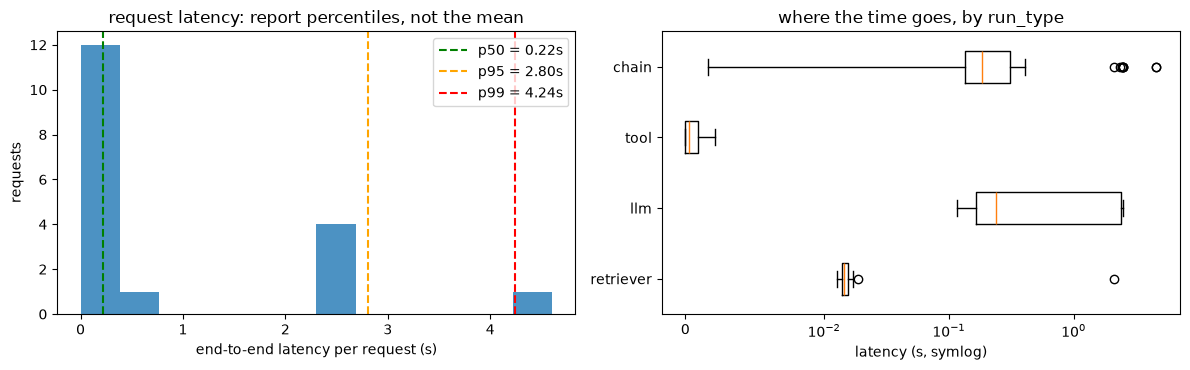

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(root_lat, bins=12, color="tab:blue", alpha=.8)
for q, c in [("p50", "green"), ("p95", "orange"), ("p99", "red")]:
    ax[0].axvline(req[q], color=c, ls="--", label=f"{q} = {req[q]:.2f}s")
ax[0].set_xlabel("end-to-end latency per request (s)"); ax[0].set_ylabel("requests"); ax[0].legend()
ax[0].set_title("request latency: report percentiles, not the mean")
if LS:
    by_type = {rt: [r.latency_seconds for r in all_runs if r.run_type == rt] for rt in ["retriever", "llm", "tool", "chain"]}
    by_type = {k: v for k, v in by_type.items() if v}
    ax[1].boxplot(list(by_type.values()), tick_labels=list(by_type.keys()), vert=False)
    ax[1].set_xscale("symlog", linthresh=0.01); ax[1].set_xlabel("latency (s, symlog)")
    ax[1].set_title("where the time goes, by run_type")
else:
    ax[1].text(.5, .5, "per-run_type breakdown needs LangSmith", ha="center", va="center"); ax[1].axis("off")
plt.tight_layout(); plt.show()

**Reading the numbers.** The `llm` runs are where the time goes. The prompt template and the tool take milliseconds; the retriever does too when the GPU is idle, and when it shows a second or two that is its query embedding waiting in Ollama's queue. Ollama's GPU is shared with other work on this machine, so absolute latencies change a lot between executions: the request p50 was 0.3 s on a quiet GPU and almost 7 s on a busy one. The shape is what to read. The two failed orders return in milliseconds, the answers spread over the rest, and the mean is pulled by both ends, which is why it is a poor summary and percentiles are the standard. The tool's error rate is 33 % (2 of 6 calls) and the request error rate is 11.1 % (2 of 18). Token counts do not depend on load: 1605 input and 270 output tokens over 18 requests, so prompts are six times longer than answers and **the retrieved context, not the answer, is the cost lever**. LangSmith left `total_cost` empty because it has no price for a local model; at our illustrative prices a request costs about $0.00002.

## 6. SLOs: turning metrics into a contract

A **service-level objective** states what "healthy" means, for example: 95 % of requests answer in under 4 s, fewer than 5 % fail, and a request uses fewer than 600 tokens on average. In production the same query runs every few minutes over a sliding window, and an alert fires when a window breaks the SLO. LangSmith can also do this itself through *automation rules* and *alerts* on a project.

### SLIs, SLOs, SLAs and error budgets

The vocabulary comes from Google's *Site Reliability Engineering* book (Beyer et al., 2016):

| term | meaning | example |
|---|---|---|
| **SLI** (indicator) | a measured quantity, usually a ratio of good events to all events | share of requests answered in under 4 s |
| **SLO** (objective) | the target for an SLI over a time window | 95 % of requests under 4 s, over 28 days |
| **SLA** (agreement) | a contract with consequences if the objective is missed | credits to a customer below 99 % availability |

The idea that makes SLOs useful is the **error budget**: a 99 % objective explicitly allows 1 % of bad events. While the budget lasts, the team can ship risky changes; when it is spent, reliability work comes first. Alerting is then based on the **burn rate**, how fast the budget is being consumed, typically checked over a short and a long window together so that a brief spike does not page anyone but a sustained one does.

LLM applications add SLIs that classical services do not have: time to first token (what users perceive in a streaming UI), tokens or cost per request, the share of answers that pass a groundedness or format check, the refusal rate, and the share of runs that end by hitting a step limit instead of answering. They are all ratios or distributions over requests, so the same SLO machinery applies.

In [12]:
SLOS = {"p95 latency (s)": (req["p95"], 4.0), "error rate": (error_rate, 0.05),
        "tokens per request": ((tok_in + tok_out) / len(records), 600)}
for name, (value, limit) in SLOS.items():
    print(f"{name:20s} {value:8.3f}  limit {limit:<6}  {'OK' if value <= limit else 'VIOLATED'}")

p95 latency (s)         2.802  limit 4.0     OK
error rate              0.111  limit 0.05    VIOLATED
tokens per request    104.167  limit 600     OK


The error-rate SLO is violated, by design: 2 of the 18 requests ask for unknown orders. Whether the latency SLO holds depends on how busy the GPU is; across our executions p95 ranged from about 3 s on a quiet GPU to about 10 s on a busy one, so this cell printed `OK` in one run and `VIOLATED` in others. That is a lesson in itself: with 18 requests, p95 is essentially the second-slowest request, so an SLO window needs hundreds of requests before its percentiles are stable enough to alert on.

## 7. Online evaluation: feedback scores on production traces

Latency and cost are easy to measure; **quality** is what users care about. In production there is no reference answer, so teams attach cheap signals to each trace as **feedback**:

- **heuristic checks** on every trace. Here `groundedness` is the share of the answer's content words (4+ letters, and every number) that appear in the retrieved context. A low value suggests the model said something the documents do not support. It is crude, and it is cheap enough to run on all traffic.
- **user feedback** (thumbs up/down, a comment) from the UI, sent with the same `create_feedback` call.
- **LLM-as-judge** online evaluators on a sample, configurable in the LangSmith UI as *automation rules*.

`client.create_feedback(run_id, key, score=..., trace_id=..., session_id=project_id)` attaches the score to the root run. Giving `trace_id` lets the SDK upload feedback in the background batch; `session_id` (the project id) is what recent LangSmith versions need to locate the run. Then we can query by feedback, which is the daily debugging loop of an LLM team: *show me the traces with the worst scores*.

### Choosing online quality signals

Without reference answers, online evaluation trades cost against fidelity. A useful way to organise the options is a pyramid, from cheap signals on all traffic to expensive ones on a sample:

| signal | cost per trace | coverage | what it catches |
|---|---|---|---|
| deterministic checks (format, length, banned strings, word-overlap groundedness) | microseconds | 100 % | broken formats, obvious hallucinations, leaks |
| small-model checks (an NLI model or embedding similarity between answer and context) | milliseconds | most traffic | statements not supported by the context |
| LLM-as-judge without a reference | a model call | a sample | relevance, faithfulness, tone |
| implicit user signals (regenerate, copy, abandon, rephrase) and explicit thumbs | free, but sparse and biased toward unhappy users | whatever users give | dissatisfaction |
| human review | minutes | a small queue, usually the worst-scored traces | ground truth, new failure categories |

Our groundedness score is the cheapest kind: a lexical overlap that ignores meaning, so it flags paraphrases as unsupported and misses a wrong number that happens to appear in the context. Model-based faithfulness metrics (for example RAGAS faithfulness, notebook 10) split the answer into claims and check each against the context; they are more accurate and far more expensive.

When a signal runs on a random sample of $n$ traces and finds a rate $\hat p$, its standard error is about $\sqrt{\hat p(1-\hat p)/n}$. A judge on 100 traces a day measures a 10 % failure rate to within roughly ±6 points (95 % interval); enough to see a large regression, not a small one. Feedback is attached to a specific run id, which is why the traffic loop above fixed one per request.

In [13]:
for r in records:
    r["groundedness"] = groundedness(r["answer"], r["contexts"]) if r["error"] is None else None
scored = [r for r in records if r["groundedness"] is not None]
print(f"mean groundedness over {len(scored)} successful requests: {np.mean([r['groundedness'] for r in scored]):.2f}")
for r in sorted(scored, key=lambda r: r["groundedness"])[:3]:
    print(f"  {r['groundedness']:.2f} | {r['question'][:50]:50s} | {r['answer'][:80]}")

if LS:
    for r in scored:
        client.create_feedback(r["run_id"], key="groundedness", score=r["groundedness"], trace_id=r["run_id"],
                               session_id=project_id, feedback_source_type="model", comment="content-word overlap with context")
    worst = min(scored, key=lambda r: r["groundedness"])
    client.create_feedback(worst["run_id"], key="user_thumbs", score=0, trace_id=worst["run_id"], session_id=project_id,
                           comment="simulated user: 'this is not what I asked'")
    client.flush()
    low = await wait_for_runs(1, is_root=True, filter=f'and(has(tags, "{EXEC_TAG}"), eq(feedback_key, "groundedness"), lt(feedback_score, 0.5))')
    print(f"\nLangSmith query 'groundedness < 0.5' returns {len(low)} traces:", [r.name for r in low])
else:
    print("skipped feedback upload: needs LangSmith")

mean groundedness over 16 successful requests: 0.81
  0.00 | Where is my order A101?                            | I don't have real-time tracking information. You should contact customer service
  0.09 | Where is my order A103?                            | I don't have real-time order tracking information. Check your original order con
  0.43 | Where is my order A100?                            | Your order A100 has been shipped and is expected to arrive in 2 days.



LangSmith query 'groundedness < 0.5' returns 3 traces: ['support_assistant', 'support_assistant', 'support_assistant']


The three lowest scores are all order-tool answers, and they are instructive. **A101 and A103 are real bugs**: the model was handed the order status and still replied that it has no real-time tracking information. Nobody looked for this; a crude heuristic on every trace surfaced it, and the fix belongs in the tool prompt. **A100 at 0.43 is a false alarm**: the answer is right, it just paraphrases the status. That is what cheap heuristics are for: ranking which traces a human should open first, not grading them. The feedback query returns those same three traces, and in the UI they carry the scores (and, for the worst one, the simulated user's thumbs-down with its comment).

## 8. Privacy: redacting PII before it leaves the process

Prompts contain user data, and traces are kept for weeks and read by many people. Personal data should be removed **before** it is sent (GDPR, SOC 2). The LangSmith `Client` has three hooks for this, all applied in your process before upload:

- `Client(hide_inputs=True, hide_outputs=True)` (or the env vars `LANGSMITH_HIDE_INPUTS=true` / `LANGSMITH_HIDE_OUTPUTS=true`) drops the payloads entirely and keeps only timing, tokens and errors. `hide_inputs` also accepts a function `dict -> dict` to keep some fields.
- `Client(anonymizer=...)` rewrites every string in inputs, outputs and metadata. `langsmith.anonymizer.create_anonymizer` builds one from regex rules (our `PII_RULES`).
- `@traceable(process_inputs=..., process_outputs=...)` does the same for one function.

Here is what our rules catch, applied locally:

In [14]:
sample = {"question": "Hi, I'm Ana (ana.lopez@example.com, +51 987 654 321). My card 4111 1111 1111 1111 was charged twice. "
                      "Debug key: sk-live_9fA3kLmN0pQrStUv"}
print(redact(dict(sample))["question"])

Hi, I'm Ana (<email>, <phone>). My card <card> was charged twice. Debug key: <api-key>


### Principles behind PII handling in traces

Traces are a copy of user data with a different purpose (debugging and evaluation) and a different audience (engineers, vendors). Data-protection law treats that copy like any other: the GDPR's principles of **data minimisation** (collect only what the purpose needs), **purpose limitation** and **storage limitation** (keep it only as long as needed) all apply to observability data. Three families of techniques, from strongest to weakest protection:

| technique | what it does | keeps |
|---|---|---|
| **drop** (`hide_inputs` / `hide_outputs`) | the payload is never sent | timing, tokens, errors |
| **redact / mask** (our anonymizer) | detected values are replaced by a type label such as `<email>` | the text around them, so traces stay readable |
| **pseudonymise** | each value is replaced by a consistent token (`<email_17>`) or a keyed hash | the ability to group traces by user without seeing who it is; legally still personal data, because the mapping exists |

Detection is the hard part. **Regular expressions** are fast and precise for values with a fixed structure (emails, card numbers, which can also be checked with the Luhn checksum, phone numbers, API keys with a known prefix), and blind to everything else. **Named-entity recognition** models (Microsoft Presidio combines both approaches) find names, addresses and organisations, at the cost of latency and of false positives and negatives. In practice teams combine them and accept that detection has a recall below 100 %, which is one more reason to limit who can read traces and for how long they are kept.

Finally, decide *where* to redact. Redacting in the tracing client protects the trace store. Redacting before the model call also protects the model provider, and redacting at the edge of the system protects everything downstream, at the price of the model never seeing the original value.

Now we trace a request through a client that has the anonymizer, and read back what LangSmith actually stored.

In [15]:
pii_client = Client(anonymizer=redact) if LS else None
pii_id = uuid.uuid4()
with tracing_context(client=pii_client, tags=[EXEC_TAG, "pii-demo"]):
    pii_answer = support_assistant(sample["question"] + " Can I still get a full refund after 10 days?",
                                   user_email="ana.lopez@example.com", langsmith_extra={"run_id": pii_id})
print("answer seen by the user:", pii_answer["answer"][:150])
if LS:
    pii_client.flush()
    pii_runs = await wait_for_runs(5, trace_id=str(pii_id), selects=RUN_FIELDS + ["INPUTS", "OUTPUTS"])
    stored = next(r for r in pii_runs if str(r.id) == str(pii_id))
    print("root inputs as stored in LangSmith:", json.dumps(stored.inputs)[:300])
    leaks = [r.name for r in pii_runs if any(x in json.dumps([r.inputs, r.outputs]) for x in ["ana.lopez", "4111", "987 654", "sk-live"])]
    print(f"runs in this trace: {len(pii_runs)} | runs whose stored inputs/outputs still contain the PII: {leaks or 'none'}")
else:
    print("skipped: needs LangSmith")

answer seen by the user: I don't know the specific details of your order or the terms for a full refund after 10 days, but typically for annual subscriptions, if cancelled wit


root inputs as stored in LangSmith: {"question": "Hi, I'm Ana (<email>, <phone>). My card <card> was charged twice. Debug key: <api-key> Can I still get a full refund after 10 days?", "user_email": "<email>"}
runs in this trace: 8 | runs whose stored inputs/outputs still contain the PII: none


The email, the phone number, the card number and the API key are replaced in the root run and in every child run of the trace (LangGraph, retriever, prompt and `ChatOllama`), because the LangChain runs nested under a `@traceable` run are sent through the same client. Two limits worth knowing: the anonymizer protects the **trace**, not the model, which still received the raw text (redact before the LLM call if the model provider must not see it); and regex rules only catch the patterns you wrote, so names like "Ana" go through.

## 9. Sampling: keeping a fraction of the traces

At high traffic you do not need every trace, and each one costs storage. `LANGSMITH_TRACING_SAMPLING_RATE=0.1` (read when a `Client` is created, so set it before the first trace) or `Client(tracing_sampling_rate=0.1)` keeps that fraction of **traces**. The decision is a hash of the trace id, so a trace is kept or dropped as a whole, never half of it. Errors are sampled like everything else, so teams that need every failure also log errors elsewhere or use a higher rate.

### Head-based and tail-based sampling

Tracing systems distinguish two moments at which the keep-or-drop decision can be made:

| | head-based sampling | tail-based sampling |
|---|---|---|
| decided | when the trace starts | after the trace has finished |
| based on | the trace id or a random draw, nothing about the outcome | anything in the trace: errors, latency, feedback, route |
| cost | negligible; dropped traces are never sent | every span must be buffered until the trace completes, usually in a collector (for example the OpenTelemetry Collector's tail-sampling processor) |
| keeps all errors? | no, errors are sampled at the same rate as successes | yes, if the policy says so |

LangSmith's client-side rate is head-based, which is why errors are sampled like everything else. The decision is made per trace, so a kept trace is always complete; dropping individual spans would leave trees with holes.

Uniform sampling keeps aggregate metrics unbiased: a rate measured on the kept traces estimates the rate on all traffic, and counts are recovered by dividing by the sampling rate. What suffers is rare events, whose counts in the sample become small and noisy. A common production compromise is to keep a small random fraction of everything plus every error and every trace with negative feedback, which requires the tail-based decision or a second, separate logging path for failures.

In [16]:
@traceable(name="tiny_request")
def tiny_request(i: int) -> int:
    return i * i

sampled_client = Client(tracing_sampling_rate=0.25) if LS else None
with tracing_context(client=sampled_client, tags=[EXEC_TAG, "sampling-demo"]):
    for i in range(40):
        tiny_request(i)
if LS:
    sampled_client.flush()
    kept = await wait_for_runs(1, filter=f'and(has(tags, "{EXEC_TAG}"), has(tags, "sampling-demo"))')
    print(f"sampling rate 0.25: LangSmith kept {len(kept)} of 40 traces")
else:
    print("skipped: needs LangSmith")

sampling rate 0.25: LangSmith kept 13 of 40 traces


Expect a count in the neighbourhood of 10, not exactly 10: each trace is kept or dropped by a hash of its random id, so the number changes between executions (we saw 7, 12 and 14). With a rate of 0.25 over 40 traces the standard deviation is about 2.7 traces.

## 10. Offline evaluation: datasets and experiments

Online scores tell you how production is doing. Before you **ship a change** you want to compare versions on the same labelled examples: that is a LangSmith **dataset**, and each scored run of a version over it is an **experiment**. `langsmith.evaluate(target, data=dataset_name, evaluators=[...])` runs the target on every example (traced, under a new experiment project), runs each evaluator on each (inputs, outputs, reference outputs) triple, and uploads the scores as feedback.

Our 12 examples are the six questions in `data/sample_eval.json` plus six more written from the same documents. The dataset name is fixed, so a rerun reuses it when the examples are unchanged and rebuilds it otherwise.

In [17]:
DATASET = "llm-edu-suite-15-support-qa"
ds_examples = [{"inputs": {"question": e["question"]}, "outputs": {"answer": e["answer"], "must_contain": e["must_contain"]}}
               for e in EVAL]
if LS:
    if client.has_dataset(dataset_name=DATASET):
        ds = client.read_dataset(dataset_name=DATASET)
        stored_qs = sorted(ex.inputs["question"] for ex in client.list_examples(dataset_id=ds.id))
        if stored_qs != sorted(e["question"] for e in EVAL):
            client.delete_dataset(dataset_id=ds.id); ds = None
    else:
        ds = None
    if ds is None:
        ds = client.create_dataset(DATASET, description="Notebook 15: support questions over data/sample_docs with key facts")
        client.create_examples(dataset_id=ds.id, examples=ds_examples)
        print("created dataset", DATASET)
    else:
        print("reusing dataset", DATASET)
    print("dataset URL:", ds.url)
else:
    print("LangSmith off: the experiments below run locally on the same", len(ds_examples), "examples")

reusing dataset llm-edu-suite-15-support-qa
dataset URL: https://smith.langchain.com/o/f25a9d41-403e-471f-904d-52820c579a17/datasets/1d527eab-6e4d-4eb4-9f3b-63c46df8b13c


### How much can a small dataset tell you?

An experiment estimates a proportion (the share of correct answers) from $n$ examples. Its standard error is about $\sqrt{p(1-p)/n}$, which is at most $0.5/\sqrt{n}$. With $n = 12$ that is up to about 0.14, so a 95 % interval spans roughly ±0.28 around the measured value; with $n = 100$ it shrinks to about ±0.10. A dataset of a dozen examples can show a large effect, such as a capability that one version has and the other lacks, but not a difference of a few points.

Two habits extract more from a small set:

- **Compare versions on the same examples** (a *paired* design). Most of the variation in a score comes from how hard each example is; running both versions on the same examples cancels it. For binary scores the matching significance test, McNemar's test, looks only at the **discordant pairs**, the examples where one version is right and the other wrong; the examples both get right or both get wrong carry no information about which is better.
- **Look at the per-example table**, not only at the averages. The examples that change verdict between versions are where the explanation is.

What goes into the dataset matters as much as its size: the common intents, the known edge cases, adversarial inputs, and every production failure that has been fixed (a regression set). Keep it versioned, so an experiment is always tied to the exact examples it ran on, and keep it out of anything used for prompt tuning, or the scores measure memorisation of the test set.

**The two versions.** `closed_book` asks the model directly, with only a system prompt saying it is the shop's assistant. `rag` is our graph. The company's policies are fictional, so a closed-book model can only guess; this is the comparison a team runs when deciding whether retrieval earns its latency.

**The evaluators** follow LangSmith's signature: a function of any of `inputs`, `outputs`, `reference_outputs` (and `run`, `example`) that returns a score, here `{"key", "score", "comment"}`.
- `exact_match`: the answer equals the reference after normalising case and punctuation. Free-text answers almost never match exactly; we include it to show why it is the wrong metric here.
- `contains_fact`: every key fact (`must_contain`) appears in the answer. Cheap and deterministic, but blind to phrasing it did not anticipate.
- `correctness`: an **LLM-as-judge**. The local `qwen2.5:3b` with structured output (a `Grade` with `reasoning` then `correct`) compares the answer with the reference, using a strict rubric. Putting the reasoning first lets the model think before it decides.

### LLM-as-judge: designs, biases and mitigations

**Three designs.** A **pointwise** judge scores one answer on a rubric. A **pairwise** judge sees two answers and picks the better one, which is closer to how humans compare and is what Chatbot Arena-style rankings use. A **reference-guided** judge compares the answer with a known correct answer, which is much more reliable for factual questions because the judge does not have to know the answer itself. Our `correctness` evaluator is pointwise and reference-guided, with a binary verdict.

**Why it works at all.** Grading is usually easier than generating: checking that an answer states the same number as a reference is a simpler task than producing that number from documents. A judge that is at least as strong as the system it grades, with a narrow rubric, can therefore be accurate enough to replace a large share of human labelling. Zheng et al. (2023) found that strong judges agree with human preferences at a level comparable to the agreement between human annotators.

**Known biases**, documented by Zheng et al. (2023), Wang et al. (2023, *Large Language Models are not Fair Evaluators*) and later work:

| bias | what happens | mitigation |
|---|---|---|
| position | in pairwise grading the verdict depends on which answer is shown first | run both orders and keep only consistent verdicts, or average them |
| verbosity | longer, more detailed answers are preferred even when they are not better | a rubric that says length is irrelevant; length-controlled comparisons |
| self-enhancement | a judge favours answers written by itself or by models of its family | use a judge from a different model family, or a panel |
| limited capability | the judge accepts wrong answers to questions it could not solve itself | give it a reference answer; keep the rubric narrow |
| prompt sensitivity | small wording changes in the judge prompt shift the scores | freeze the judge prompt and version it like code |
| score-scale drift | 1 to 10 scales are used inconsistently | binary or few-level verdicts with explicit criteria; G-Eval (Liu et al., 2023) weights scores by the judge's token probabilities |

**Good practice** that the evaluator below follows: a structured output with the **reasoning before the verdict** (the model writes its justification first, so the verdict is conditioned on it, the same idea as chain-of-thought), temperature 0, a strict rubric that defines what counts as correct, and the judge's comment kept with each score so a human can audit it. A **panel** of several smaller judges from different families can match one large judge at lower cost and with less self-preference (Verga et al., 2024).

**Validate the judge before trusting it.** Label a few dozen answers by hand and measure agreement. Raw agreement is inflated when one class dominates, so use Cohen's kappa, which corrects for agreement by chance:

$$
\kappa = \frac{p_o - p_e}{1 - p_e},
$$

where $p_o$ is the observed agreement and $p_e$ the agreement expected if both raters labelled at random with their own label frequencies. Below, the deterministic `contains_fact` check plays the role of the second rater, an imperfect but free stand-in for human labels.

In [ ]:
closed_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are the customer support assistant of an online shop. Answer the question in one sentence."),
    ("human", "{question}"),
])
closed_chain = closed_prompt | llm

def closed_book(inputs: dict) -> dict:
    return {"answer": closed_chain.invoke({"question": inputs["question"]}).content}

def rag(inputs: dict) -> dict:
    out = rag_graph.invoke({"question": inputs["question"]})
    return {"answer": out["answer"], "contexts": [d.page_content for d in out["docs"]]}

from llm_edu_suite.config import get_judge_llm
correctness = make_correctness_judge(get_judge_llm())      # qwen2.5:7b if pulled: a stronger model grades the 3B app
EVALUATORS = [exact_match, contains_fact, correctness]

def run_locally(target, examples, evaluators) -> list:
    """What evaluate() does, minus the upload: run the target on each example and score it."""
    rows = []
    for ex in examples:
        out = target(ex["inputs"])
        scores = {}
        for ev in evaluators:
            kw = {"inputs": ex["inputs"], "outputs": out, "reference_outputs": ex["outputs"]}
            res = ev(**{k: v for k, v in kw.items() if k in ev.__code__.co_varnames})
            scores[res["key"]] = res["score"]
            if "comment" in res: scores[res["key"] + "_comment"] = res["comment"]
        rows.append({"question": ex["inputs"]["question"], "answer": out["answer"], **scores})
    return rows

os.environ["TQDM_DISABLE"] = "1"                   # evaluate() shows a tqdm progress bar; keep the notebook output readable
warnings.filterwarnings("ignore", message="IProgress not found")
results, experiment_urls = {}, {}
for name, target in [("closed_book", closed_book), ("rag", rag)]:
    t0 = time.time()
    if LS:
        exp = evaluate(target, data=DATASET, evaluators=EVALUATORS, experiment_prefix=f"nb15-{name}",
                       metadata={"variant": name, "model": MODEL}, max_concurrency=2)
        rows = []
        for row in exp:
            scores = {e.key: e.score for e in row["evaluation_results"]["results"]}
            scores.update({e.key + "_comment": e.comment for e in row["evaluation_results"]["results"] if e.comment})
            rows.append({"question": row["example"].inputs["question"], "answer": row["run"].outputs["answer"], **scores})
        experiment_urls[name] = exp.url
    else:
        rows = run_locally(target, ds_examples, EVALUATORS)
    results[name] = rows
    print(f"{name:12s} {time.time() - t0:5.1f}s  " + "  ".join(f"{k} {np.mean([r[k] for r in rows]):.2f}" for k in ["exact_match", "contains_fact", "correctness"]))

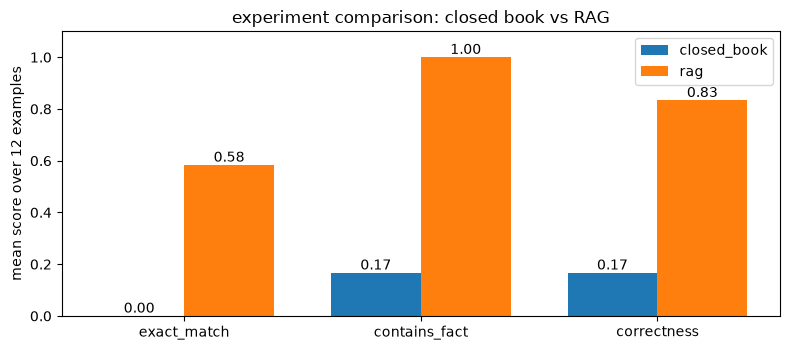

per example (contains_fact / correctness):
  Are gift cards refundable?                       closed 1/0   rag 1/0
  How is customer data encrypted?                  closed 0/0   rag 1/1
  How long does express shipping take?             closed 1/1   rag 1/1
  How long does standard shipping take?            closed 0/0   rag 1/1
  How many characters must a password have?        closed 0/0   rag 1/1
  How many days do I have to request a full refund closed 0/1   rag 1/1
  How much does express shipping cost?             closed 0/0   rag 1/1
  How quickly are refunds processed?               closed 0/0   rag 1/1
  What is the rate limit of the public API?        closed 0/0   rag 1/1
  What response time do enterprise customers get?  closed 0/0   rag 1/1
  When do sessions expire?                         closed 0/0   rag 1/1
  When is chat support available?                  closed 0/0   rag 1/0

judge agrees with contains_fact on 83% of the 24 answers; the disagreements:
  [closed_book]

In [19]:
keys = ["exact_match", "contains_fact", "correctness"]
fig, ax = plt.subplots(figsize=(8, 3.6))
w = 0.38
for i, (name, rows) in enumerate(results.items()):
    vals = [np.mean([r[k] for r in rows]) for k in keys]
    bars = ax.bar(np.arange(len(keys)) + (i - .5) * w, vals, w, label=name)
    ax.bar_label(bars, fmt="%.2f")
ax.set_xticks(range(len(keys)), keys); ax.set_ylim(0, 1.1); ax.set_ylabel(f"mean score over {len(EVAL)} examples")
ax.set_title("experiment comparison: closed book vs RAG"); ax.legend(); plt.tight_layout(); plt.show()

print("per example (contains_fact / correctness):")
rag_by_q = {r["question"]: r for r in results["rag"]}         # experiments may return examples in different orders
for a in sorted(results["closed_book"], key=lambda r: r["question"]):
    b = rag_by_q[a["question"]]
    print(f"  {a['question'][:48]:48s} closed {a['contains_fact']:.0f}/{a['correctness']:.0f}   rag {b['contains_fact']:.0f}/{b['correctness']:.0f}")
both = [r for rows in results.values() for r in rows]
agree = np.mean([r["contains_fact"] == r["correctness"] for r in both])
print(f"\njudge agrees with contains_fact on {agree:.0%} of the {len(both)} answers; the disagreements:")
for name, rows in results.items():
    for r in rows:
        if r["contains_fact"] != r["correctness"]:
            print(f"  [{name}] contains_fact {r['contains_fact']:.0f}, judge {r['correctness']:.0f} | {r['question']}\n"
                  f"      answer: {r['answer'][:110]}\n      judge : {r.get('correctness_comment', '')[:110]}")

**Retrieval is what makes this app work.** The closed-book version gets the key fact in 2 of 12 answers (`contains_fact` 0.17) and the judge accepts 2 (0.17); its few hits are generic guesses that happen to match ("1-2 business days" for express shipping). With retrieval, every answer contains the key fact (1.00) and the judge accepts 10 of 12 (0.83). Everything runs at temperature 0, so the answers barely change between executions, but the judge's verdict on a borderline answer can flip: in an earlier execution the same RAG app scored 0.92. That is normal for an LLM judge and one more reason to read its comments, not only its average.

`exact_match` is 0.00 for closed book and 0.58 for RAG. The RAG model often copies the document sentence, and our reference answers were written from those sentences, so 7 answers match word for word; the other correct answers are phrased differently and score 0. For free text, exact match measures phrasing, not correctness.

The judge agrees with `contains_fact` on 20 of the 24 answers. The four disagreements show what each evaluator misses. Once the judge is clearly right where the keyword check is fooled: the RAG answer on gift cards adds a false claim (a store-credit refund within 30 days). Once it applies our no-hedging rule to the closed-book "gift cards are *typically* not refundable". And twice it is wrong: it rejected the correct RAG answer on chat hours because it adds the time zone (which is in the document), and it accepted a closed-book answer that gives no number at all ("refer to your order confirmation"). A 3B judge is useful, but it should be checked against deterministic evaluators, or a few human labels, before you trust its numbers.

## 11. Export: getting the data out

Traces are data, and teams join them with business data, build dashboards or fine-tuning sets from them. The options:

- the SDK query we used, written to **JSON Lines** for any pipeline (below);
- LangSmith **bulk export** of a project to S3-compatible storage (Parquet), configured in the UI or the API;
- **OpenTelemetry**: with `LANGSMITH_OTEL_ENABLED=true` the SDK can send runs as OTel spans, and LangSmith also *accepts* OTLP traces, so it fits into a Grafana/Datadog stack.

In [20]:
path = os.path.join(tempfile.gettempdir(), "nb15_runs.jsonl")
if LS:
    with open(path, "w", encoding="utf-8") as f:
        for r in all_runs:
            f.write(json.dumps({"id": r.id, "trace_id": r.trace_id, "name": r.name, "run_type": r.run_type, "status": r.status,
                                "latency_s": r.latency_seconds, "prompt_tokens": r.prompt_tokens,
                                "completion_tokens": r.completion_tokens, "tags": r.tags}) + "\n")
    print(f"exported {len(all_runs)} runs to {path}; first line:")
    print(open(path, encoding="utf-8").readline()[:300])
else:
    print("skipped: needs LangSmith")

exported 112 runs to C:\Users\Andy\AppData\Local\Temp\nb15_runs.jsonl; first line:
{"id": "01a1bedd-ff6b-7424-a84f-12a2c2f381a6", "trace_id": "8b143a8c-3581-45da-be41-a5b63f99612b", "name": "ollama_chat_rest", "run_type": "llm", "status": "success", "latency_s": 2.4332191944122314, "prompt_tokens": 48, "completion_tokens": 20, "tags": ["exec-c721fdcc", "traffic", "support"]}



## 12. Where to look in the LangSmith UI

Everything above is also in the web app, which is where you will spend most of your time:

- **Project → Runs**: the traces of this notebook. Click one for the tree from section 2; filter with `has(tags, "traffic")` or by feedback (`groundedness < 0.5`). The *Monitor* tab charts latency, tokens, errors and feedback over time.
- **Project → Threads**: the three-turn conversation from section 4.
- **Datasets & Experiments → `llm-edu-suite-15-support-qa`**: the two experiments side by side, per example, with the judge's reasoning as a comment on each `correctness` score.

In [21]:
if LS:
    print("project    :", client.read_project(project_name=PROJECT).url)
    print("dataset    :", ds.url)
    for name, url in experiment_urls.items():
        print(f"experiment : {name:12s} {url}")
else:
    print("LangSmith is off: add LANGSMITH_TRACING=true and LANGSMITH_API_KEY to .env to get the links")

project    : https://smith.langchain.com/o/f25a9d41-403e-471f-904d-52820c579a17/projects/p/953e8352-cea9-4165-b5e2-bd31a7a3cca5
dataset    : https://smith.langchain.com/o/f25a9d41-403e-471f-904d-52820c579a17/datasets/1d527eab-6e4d-4eb4-9f3b-63c46df8b13c
experiment : closed_book  https://smith.langchain.com/o/f25a9d41-403e-471f-904d-52820c579a17/datasets/1d527eab-6e4d-4eb4-9f3b-63c46df8b13c/compare?selectedSessions=16c3f277-ab86-4d16-aed7-e7adc7be10e0
experiment : rag          https://smith.langchain.com/o/f25a9d41-403e-471f-904d-52820c579a17/datasets/1d527eab-6e4d-4eb4-9f3b-63c46df8b13c/compare?selectedSessions=551943c9-7e44-472b-b91a-2cb8375956fe


## Evaluation

| metric (this execution) | value |
|---|---|
| experiment `closed_book`: exact_match / contains_fact / correctness | 0.00 / 0.17 / 0.17 |
| experiment `rag`: exact_match / contains_fact / correctness | 0.58 / 1.00 / 0.83 |
| LLM judge vs `contains_fact` agreement | 20 / 24 answers |
| traffic: requests, error rate | 18, 11.1 % (the two unknown orders) |
| tokens per request (input + output) | 104 (1605 in, 270 out over 18 requests) |
| request latency p50 / p95 | 0.22 s / 2.8 s in this execution on a free GPU (up to ~7 s / 10 s when the GPU was shared) |
| online groundedness, mean over 16 successful requests | 0.81, with two real tool-prompt bugs among the three lowest |

The practitioner's summary: retrieval lifts judged correctness from 0.17 to 0.83 at the price of a longer prompt (the RAG prompt in section 2 has 115 input tokens); the order-tool prompt needs a fix (found by online feedback, not by the offline set, which has no order questions); and error rate breaks its SLO by design.

## Takeaways

| what to record | how in LangSmith | why |
|---|---|---|
| a trace per request, a run per step | automatic for LangChain/LangGraph, `@traceable` for the rest | debugging, latency breakdown |
| model, tokens in/out per LLM run | automatic for chat models; `usage_metadata` for your own `llm` runs | cost control, regressions after prompt changes |
| version, user, route, conversation | `tags`, `metadata`, `thread_id` | filtering, threads, A/B comparisons |
| errors | raised exceptions are recorded on the run | error rate, alerting |
| quality | `create_feedback` online, `evaluate()` offline | finding bad answers, deciding what ships |
| privacy | `anonymizer`, `hide_inputs` / `hide_outputs` | no personal data in traces |

- Report **p50/p95/p99**, not only the mean, and write SLOs down so a breach is a fact, not an opinion.
- Measure quality with several signals: deterministic checks where you can, an LLM judge where you must, and check the judge against them (or against humans) before trusting it.
- Compare versions on a fixed dataset **before** shipping; watch online feedback **after**.

**Next:** `16_mcp_model_context_protocol.ipynb`.